<h1>Random Sequential Model for two Substrates</h1>
<h3>Comparison of alternative models</h3>
<h3>Model as opposed to the "Ordered Theorell-Chance model"</h3>
<p>G. Woehlke 2015 ff (converted from Wolfram Mathematica, aided by A.I.)</p>
<p>This version calculates the time trace (not the equilibrium state)</p>

<h3>Kinetic scheme: </h3> 
<p>Several oxidoreducases oxidize alcohol to aldehyde, and confer the reducing equivalents to NAD+. Upon binding the alcohol, the enzyme is able to accept NAD+, and release the products quickly without detectable trinary intermediate EAB. 
However, an alternative may be the random sequential binding of either substrate. This random sequential reaction scheme may be analyzed by: </p>
<img src="2-10_RandomBi.png" width="466"> 
<p>This gives the following set of steady state equations:</p><ol>
<li>$d{c}_{EA}/dt = k_{12} c_{A}(t) c_{E}(t)-k_{24} c_{B}(t) c_{EA}(t)-k_{21} c_{EA}(t)+k_{42} c_{EAB}(t)$</li>
<li>$d{c}_{EB}/dt = -k_{34} c_{A}(t) c_{EB}(t)+k_{13} c_{B}(t) c_{E}(t)+k_{43} c_{EAB}(t)-k_{31} c_{EB}(t)$</li>
<li>$d{c}_{EAB}/dt = k_{14} (0(t))^2 c_{E}(t)+k_{34} c_{A}(t) c_{EB}(t)+k_{24} c_{B}(t) c_{EA}(t)-k_{41} c_{EAB}(t)-k_{42} c_{EAB}(t)-k_{43} c_{EAB}(t)$</li>
<li>$E_{total}=c_{E}(t)+c_{EA}(t)+c_{EAB}(t)+c_{EB}(t)$ </li>
</ol>

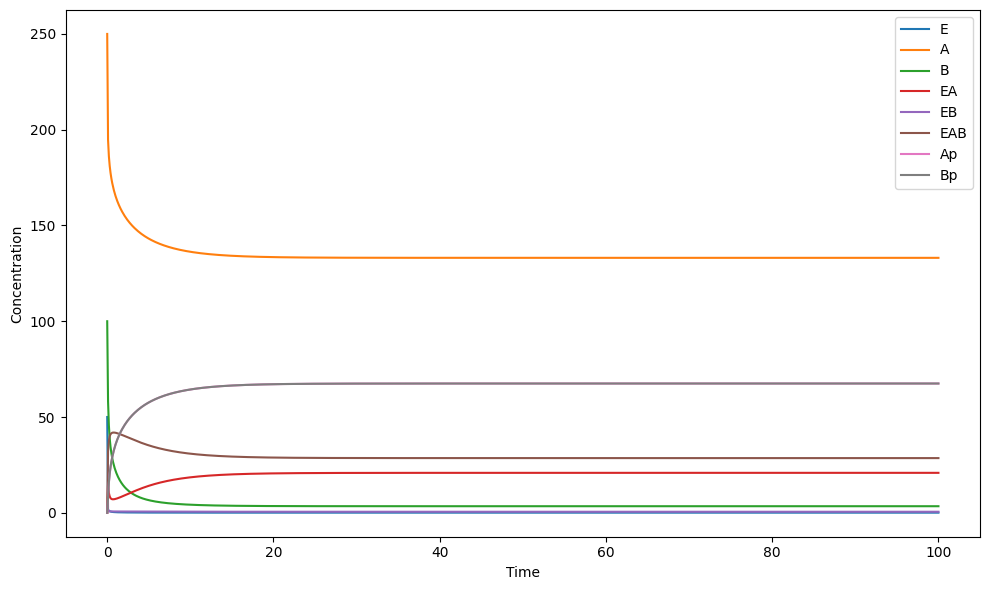

In [6]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# ---------------------------
# Parameters
# ---------------------------

k12 = 0.25
k21 = 0.10
k24 = 0.20
k42 = 0.50
k13 = 0.25
k31 = 0.10
k34 = 0.20
k43 = 0.50
k41 = 5.0
k14 = 0.50

# ---------------------------
# Initial conditions
# ---------------------------

E0   = 50
A0   = 250
B0   = 100
EA0  = 0
EB0  = 0
EAB0 = 0
Ap0  = 0
Bp0  = 0

y0 = [E0, A0, B0, EA0, EB0, EAB0, Ap0, Bp0]

# ---------------------------
# Time interval
# ---------------------------

t_end = 100.0

# ---------------------------
# ODE system
# ---------------------------

def reaction_system(t, y):
    E, A, B, EA, EB, EAB, Ap, Bp = y

    # Reaction rates
    r12 = k12 * E * A
    r21 = k21 * EA

    r24 = k24 * EA * B
    r42 = k42 * EAB

    r13 = k13 * E * B
    r31 = k31 * EB

    r34 = k34 * EB * A
    r43 = k43 * EAB

    r41 = k41 * EAB
    r14 = k14 * Ap * Bp * E

    # Differential equations
    dE   = -r12 + r21 - r13 + r31 + r41 - r14
    dA   = -r12 + r21 - r34 + r43
    dB   = -r24 + r42 - r13 + r31

    dEA  =  r12 - r21 - r24 + r42
    dEB  =  r13 - r31 - r34 + r43

    dEAB =  r24 - r42 + r34 - r43 - r41 + r14

    dAp  =  r41 - r14
    dBp  =  r41 - r14

    return [dE, dA, dB, dEA, dEB, dEAB, dAp, dBp]

# ---------------------------
# Numerical solution
# ---------------------------

t_eval = np.linspace(0, t_end, 1000)

sol = solve_ivp(
    reaction_system,
    (0, t_end),
    y0,
    t_eval=t_eval,
    method="LSODA"   # good choice for biochemical kinetics
)

# ---------------------------
# Plot
# ---------------------------

labels = ["E", "A", "B", "EA", "EB", "EAB", "Ap", "Bp"]

plt.figure(figsize=(10, 6))

for i, label in enumerate(labels):
    plt.plot(sol.t, sol.y[i], label=label)

plt.xlabel("Time")
plt.ylabel("Concentration")
plt.legend()
plt.tight_layout()
plt.show()

<h2>Interactive version:</h2>

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

import ipywidgets as widgets
from ipywidgets import interact

# =====================================================
# Solve the ODE system once
# =====================================================

k12 = 0.25
k21 = 0.10
k24 = 0.20
k42 = 0.50
k13 = 0.25
k31 = 0.10
k34 = 0.20
k43 = 0.50
k41 = 5.0
k14 = 0.50

def reaction_system(t, y):

    E, A, B, EA, EB, EAB, Ap, Bp = y

    r12 = k12 * E * A
    r21 = k21 * EA

    r24 = k24 * EA * B
    r42 = k42 * EAB

    r13 = k13 * E * B
    r31 = k31 * EB

    r34 = k34 * EB * A
    r43 = k43 * EAB

    r41 = k41 * EAB
    r14 = k14 * Ap * Bp * E

    dE   = -r12 + r21 - r13 + r31 + r41 - r14
    dA   = -r12 + r21 - r34 + r43
    dB   = -r24 + r42 - r13 + r31

    dEA  =  r12 - r21 - r24 + r42
    dEB  =  r13 - r31 - r34 + r43

    dEAB =  r24 - r42 + r34 - r43 - r41 + r14

    dAp  =  r41 - r14
    dBp  =  r41 - r14

    return [dE, dA, dB, dEA, dEB, dEAB, dAp, dBp]


y0 = [50, 250, 100, 0, 0, 0, 0, 0]

t_end = 100.0

t = np.linspace(0.001, t_end, 2000)

sol = solve_ivp(
    reaction_system,
    (0, t_end),
    y0,
    t_eval=t,
    method="LSODA"
)

labels = ["cE", "cA", "cB", "cEA", "cEB", "cEAB", "cAp", "cBp"]

# =====================================================
# Interactive plotting function
# =====================================================

def plot_model(
    grid=True,
    font_size=18,
    line_thickness=2.5,
    image_width=900,
    tE=t_end
):

    fig_height = image_width / 150
    fig_width  = image_width / 100

    plt.figure(figsize=(fig_width, fig_height))

    mask = sol.t <= tE

    for i, label in enumerate(labels):
        plt.semilogx(
            sol.t[mask],
            sol.y[i][mask],
            linewidth=line_thickness,
            label=label
        )

    plt.xlabel("log(time)", fontsize=font_size)
    plt.ylabel("concentrations", fontsize=font_size)

    plt.title(
        "ADH (Random Sequential Model)",
        fontsize=font_size + 2
    )

    plt.legend(fontsize=max(8, font_size-4))

    plt.tick_params(
        axis='both',
        labelsize=font_size-2
    )

    plt.grid(grid)

    plt.tight_layout()
    plt.show()

# =====================================================
# Interactive controls (Mathematica Manipulate analogue)
# =====================================================

interact(
    plot_model,

    grid=widgets.Dropdown(
        options=[("None", False),
                 ("Automatic", True)],
        value=True,
        description="Grid"
    ),

    font_size=widgets.Dropdown(
        options=[12,14,18,24,28,36],
        value=18,
        description="Font"
    ),

    line_thickness=widgets.Dropdown(
        options=[1.5,2.5,4,5,7],
        value=2.5,
        description="Width"
    ),

    image_width=widgets.Dropdown(
        options=[450,650,720,900,1200,1920],
        value=900,
        description="Size"
    ),

    tE=widgets.FloatSlider(
        value=t_end,
        min=0.2,
        max=t_end,
        step=0.2,
        description="x-range",
        continuous_update=False
    )
);

interactive(children=(Dropdown(description='Grid', index=1, options=(('None', False), ('Automatic', True)), va…